## 1 Sampling intervalls

count    1.351664e+07
mean     1.626587e+01
std      3.214699e+02
min      1.666667e-02
25%      5.000000e+00
50%      1.000000e+01
75%      2.998333e+01
max      4.220400e+05
Name: gap_mn, dtype: float64


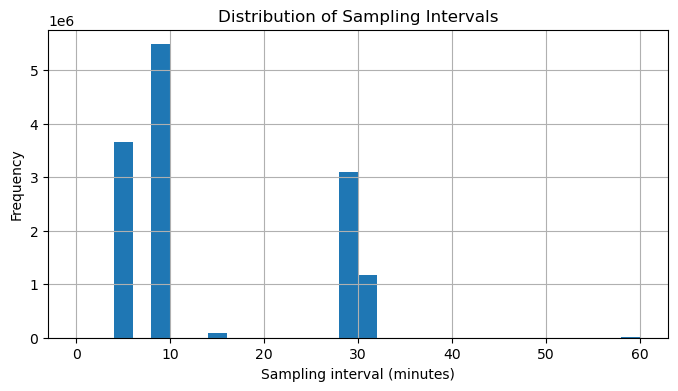

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

path = r"D:\DCU\Sem2\Data analysis and mining\Project\dublin_bikes_all.csv"
df = pd.read_csv(path)

df["last_reported"] = pd.to_datetime(df["last_reported"], errors="coerce")

df = df.sort_values(["station_id", "last_reported"])

# gap in seconds between consecutive reports for the same station
df["gap"] = df.groupby("station_id")["last_reported"].diff()
df["gap_mn"] = df["gap"].dt.total_seconds() / 60 # in minutes (mn)
print(df["gap_mn"].describe())


plt.figure(figsize=(8,4))

df["gap_mn"].dropna().clip(upper=60).hist(bins=30)

plt.xlabel("Sampling interval (minutes)")
plt.ylabel("Frequency")
plt.title("Distribution of Sampling Intervals")

plt.show()


In [2]:
# Rolling mean per station

# Feature
df["utilisation"] = df["num_bikes_available"] / df["capacity"]

# Sort + set time index (required for time-based rolling)
df = df.sort_values(["station_id", "last_reported"]).set_index("last_reported")

# Time-based rolling mean per station (drop station_id level to align)
rolling = (
    df.groupby("station_id")["utilisation"]
      .rolling("30min", min_periods=1)
)
df["roll_mean_30min"] = rolling.mean().reset_index(level=0, drop=True)
df["roll_std_30min"]  = rolling.std().reset_index(level=0, drop=True)

'''df["roll_mean_30min"] = (
    df.groupby("station_id")["utilisation"]
      .rolling("30min", min_periods=1)
      .mean()
      .reset_index(level=0, drop=True)   # <-- critical line
)'''

# Restore last_reported as a column
df = df.reset_index()

## 3- Weekly view for one station

count                         1205
mean     0 days 00:08:21.659751037
std      0 days 00:21:41.639867985
min                0 days 00:05:00
25%                0 days 00:05:00
50%                0 days 00:05:00
75%                0 days 00:10:00
max                0 days 09:30:00
Name: last_reported, dtype: object
CLARENDON ROW


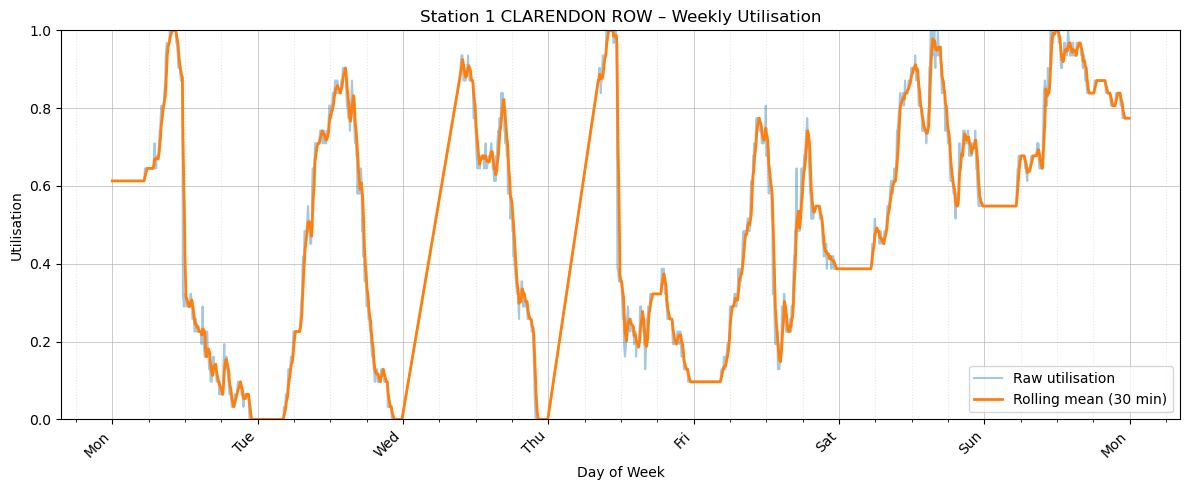

In [3]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
import matplotlib.ticker as ticker




start = pd.Timestamp("2024-06-03")
end   = pd.Timestamp("2024-06-10")

station_id = 1

station_df = df[
    (df["station_id"] == station_id) &
    (df["last_reported"] >= start) &
    (df["last_reported"] < end)
].sort_values("last_reported")

# # Checks on data missing / mismatch...
## this is on the original df, for all years for this specific station, to check if the sampling interval is consistent
print(station_df["last_reported"].diff().describe())


station_name = station_df["name"].iloc[0]
print(station_name)
week = station_df[(station_df["last_reported"] >= start) & (station_df["last_reported"] < end)]

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(week["last_reported"], week["utilisation"], alpha=0.4, label="Raw utilisation")
ax.plot(week["last_reported"], week["roll_mean_30min"], linewidth=2, label="Rolling mean (30 min)")

# Fix y-axis
ax.set_ylim(0, 1.0)

# Major ticks: one per day (at midnight)
ax.xaxis.set_major_locator(mdates.DayLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a"))  # Mon Tue Wed...

# Minor ticks = every 6 hours
ax.xaxis.set_minor_locator(mdates.HourLocator(byhour=[0,6,12,18]))

# Grid
ax.grid(True, which="major", linewidth=0.5, alpha=0.9)
ax.grid(True, which="minor", linestyle=":", alpha=0.3)

# Rotate only the major tick labels
for label in ax.get_xticklabels(which="major"):
    label.set_rotation(45)
    label.set_ha("right")

ax.set_title(f"Station {station_id} {station_name} – Weekly Utilisation")
ax.set_xlabel("Day of Week")
ax.set_ylabel("Utilisation")
ax.legend()

# Grid: only on major ticks to avoid vertical stripe overload
# ax.grid(True, which="major", alpha=0.3)

plt.tight_layout()
plt.show()

## 4- New DataFrame Creation

In [4]:
# Dock ratio: ratio of docks available to capacity
df["dock_ratio"] = df["num_docks_available"] / df["capacity"]

# Hour slot: 0-23, where 0 is midnight and 23 is 11 PM
df["hour_slot"] = df["last_reported"].dt.floor("h")

# Days of week: 0-6, where 0 is Monday and 6 is Sunday
df["days_of_week"] = df["last_reported"].dt.dayofweek
df["is_weekday"] = df["days_of_week"] < 5

# Risk: less than 5% of bikes available
df["full_risk"] = df["utilisation"] < 0.05

# Antirisk: more than 95% of bikes available
df["zero_risk"] = df["utilisation"] > 0.95

# Features
feature_cols = ["station_id", "hour_slot", "is_weekday", "roll_mean_30min", "roll_std_30min", "utilisation", "dock_ratio", "full_risk", "zero_risk"]


# Create new DataFrame with features
df_features = df[feature_cols].copy()

print(df_features.head(20))
df_features.describe()

    station_id           hour_slot  is_weekday  roll_mean_30min  \
0            1 2022-04-27 13:00:00        True              0.0   
1            1 2022-04-27 13:00:00        True              0.0   
2            1 2022-04-27 14:00:00        True              0.0   
3            1 2022-04-27 14:00:00        True              0.0   
4            1 2022-04-27 15:00:00        True              0.0   
5            1 2022-04-27 15:00:00        True              0.0   
6            1 2022-04-27 16:00:00        True              0.0   
7            1 2022-04-27 16:00:00        True              0.0   
8            1 2022-04-27 17:00:00        True              0.0   
9            1 2022-04-27 17:00:00        True              0.0   
10           1 2022-04-27 18:00:00        True              0.0   
11           1 2022-04-27 18:00:00        True              0.0   
12           1 2022-04-27 19:00:00        True              0.0   
13           1 2022-04-27 19:00:00        True              0.

,station_id,hour_slot,roll_mean_30min,roll_std_30min,utilisation,dock_ratio
count,1.351676e+07,13516758,1.351676e+07,1.040721e+07,1.351676e+07,1.351676e+07
mean,5.839655e+01,2024-05-29 08:26:04.568248832,3.801650e-01,1.982916e-02,3.802120e-01,6.110880e-01
min,1.000000e+00,2022-01-01 00:00:00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2.900000e+01,2023-09-19 14:00:00,1.034483e-01,0.000000e+00,1.000000e-01,3.750000e-01
50%,5.800000e+01,2024-09-02 07:00:00,3.250000e-01,1.397542e-02,3.250000e-01,6.666667e-01
75%,8.800000e+01,2025-03-18 06:00:00,6.000000e-01,2.788867e-02,6.000000e-01,8.947368e-01
max,5.070000e+02,2025-08-31 23:00:00,1.000000e+00,7.071068e-01,1.000000e+00,1.050000e+00
std,3.458595e+01,NaN,3.027811e-01,3.130039e-02,3.041146e-01,3.070822e-01


# 5- Proximity feature

In [5]:
!pip install osmnx

   ---------------------------------------- 0.0/104.4 kB ? eta -:--:--
   --------------- ------------------------ 41.0/104.4 kB ? eta -:--:--
   ---------------------------------------  102.4/104.4 kB 1.5 MB/s eta 0:00:01
   ---------------------------------------- 104.4/104.4 kB 1.2 MB/s eta 0:00:00
   ---------------------------------------- 0.0/341.7 kB ? eta -:--:--
   ------- -------------------------------- 61.4/341.7 kB 1.7 MB/s eta 0:00:01
   -------------- ------------------------- 122.9/341.7 kB 1.4 MB/s eta 0:00:01
   ----------------------- ---------------- 204.8/341.7 kB 1.6 MB/s eta 0:00:01
   ----------------------------- ---------- 256.0/341.7 kB 1.4 MB/s eta 0:00:01
   -------------------------------------- - 327.7/341.7 kB 1.4 MB/s eta 0:00:01
   ---------------------------------------- 341.7/341.7 kB 1.4 MB/s eta 0:00:00
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   - -------------------------------------- 0.1/1.7 MB 1.3 MB/s eta 0:00:02
  

In [6]:
import numpy as np

stations = df[["station_id","lat","lon"]].drop_duplicates()

# Considered as Dublin city center : O Connell Bridge
center_lat = 53.3498
center_lon = -6.2603

# Distance to the center
stations["distance_center"] = np.sqrt((stations["lat"] - center_lat)**2 +(stations["lon"] - center_lon)**2)

# Classification
def center_category(d):
    # Below 1km
    if d < 0.01:
        return 1

    # Betwteen 1km and 2km
    elif d < 0.02:
        return 2

    # Over 2km
    else:
        return 3

stations["center_index"] = stations["distance_center"].apply(center_category)

print(stations[["station_id","center_index"]].head())

        station_id  center_index
0                1             1
32233            1             1
119533           2             2
157347           2             2
233722           3             1


In [7]:
import osmnx as ox

def getArea(lat, lon):

  tags = {"landuse": True, "tourism": True}
  gdf = ox.features_from_point((lat, lon), tags=tags, dist=150)

  # Default area
  area = "residential"
  tourism = False

  # Check that the column "landuse" exists and contains at least one valid value
  if "landuse" in gdf.columns and gdf["landuse"].notna().any():
      # Keep the most relevant area
      land = gdf["landuse"].value_counts().idxmax()

      if land in ["commercial", "industrial", "education"]:
          area = "work"
      elif land == "retail":
          area = "retail"

  if "tourism" in gdf.columns and gdf["tourism"].notna().any() or land == "park":
      tourism = True

  print([area, tourism])
  return [area, tourism]

In [8]:
stations["area_type"] = stations.apply(lambda row: getArea(row["lat"], row["lon"]),
    axis=1
)

['retail', True]
['retail', True]
['residential', True]
['residential', True]
['residential', True]
['residential', True]
['residential', True]
['residential', True]
['residential', True]
['residential', True]
['work', True]
['work', True]
['residential', True]
['residential', True]


KeyboardInterrupt: 

# 6 Average/Total number of bikes


In [ ]:

df = df.sort_values(["station_id", "last_reported"])



# Resample every 30 minutes per station, using mean of utilisation/dock_ratio
resampled = (
    df.groupby("station_id")
      .resample("30min")
      .agg({
          "utilisation": "mean",
          "dock_ratio": "mean",
          "num_bikes_available": "mean",
          "capacity": "first"      # capacity usually constant
      })
      .reset_index()
)

# This is now one row per station per 30‑min slot with average bikes and utilisation.


In [14]:
# Recomputing the rolling mean and rolling std again on this resampled data

resampled = resampled.sort_values(["station_id", "last_reported"])

# e.g., 2 slots = 1 hour of history if you used 30min slots
resampled["roll_mean_30min"] = (
    resampled.groupby("station_id")["utilisation"]
             .rolling(window=2, min_periods=1)
             .mean()
             .reset_index(level=0, drop=True)
)

resampled["roll_std_30min"] = (
    resampled.groupby("station_id")["utilisation"]
             .rolling(window=2, min_periods=1)
             .std()
             .reset_index(level=0, drop=True)
             .fillna(0)
)


In [15]:
# doing the same features done above on the resampled data

resampled["hour_slot"] = resampled["last_reported"].dt.floor("h")
resampled["day_of_week"] = resampled["last_reported"].dt.dayofweek
resampled["is_weekday"] = (resampled["day_of_week"] < 5).astype(int)

# Risk / anti-risk based on utilisation fraction
resampled["full_risk"] = (resampled["utilisation"] < 0.05).astype(int)
resampled["zero_risk"] = (resampled["utilisation"] > 0.95).astype(int)

# Example centre proximity (replace with your logic / station list)
centre_ids = {1, 2, 3}
resampled["centre_proximity"] = resampled["station_id"].isin(centre_ids).astype(int)


In [ ]:
#Now calculating the average bikes

# Average bikes per station

avg_bikes_per_station = (
    df.groupby("station_id")["num_bikes_available"]
      .mean()
      .reset_index(name="avg_available_bikes")
)
print(avg_bikes_per_station.head())


   station_id  avg_available_bikes
0           1            14.940067
1           2             4.888238
2           3             8.903841
3           4             9.859526
4           5            19.533802


In [23]:
df["num_bikes_available"] = df["utilisation"] * df["capacity"]


In [29]:
# Total bikes per station per hour 
hourly_total = (
    df.groupby(["station_id", "hour_slot"])["num_bikes_available"]
      .sum()
      .reset_index(name="total_bikes_per_hour")
)

print(hourly_total.head(10))
print(hourly_total["total_bikes_per_hour"].describe())


   station_id           hour_slot  total_bikes_per_hour
0           1 2022-04-27 13:00:00                   0.0
1           1 2022-04-27 14:00:00                   0.0
2           1 2022-04-27 15:00:00                   0.0
3           1 2022-04-27 16:00:00                   0.0
4           1 2022-04-27 17:00:00                   0.0
5           1 2022-04-27 18:00:00                   0.0
6           1 2022-04-27 19:00:00                   0.0
7           1 2022-04-27 20:00:00                   0.0
8           1 2022-04-27 21:00:00                   0.0
9           1 2022-04-27 22:00:00                   0.0
count    3.382818e+06
mean     4.760139e+01
std      6.000109e+01
min      0.000000e+00
25%      1.000000e+01
50%      2.700000e+01
75%      5.600000e+01
max      4.800000e+02
Name: total_bikes_per_hour, dtype: float64


# there were a lot of zeroes so below i just checked if the code is correct by checking if there are any non zeroes

In [ ]:
# Total bikes per station per hour
hourly_total = (
    df.groupby(["station_id", "hour_slot"])["num_bikes_available"]
      .sum()
      .reset_index(name="total_bikes_per_hour")
)

# Checking non-zero hours
non_zero_hours = hourly_total[hourly_total["total_bikes_per_hour"] > 0]
print(f"Total station-hours: {len(hourly_total):,}")
print(f"Non-zero bike hours: {len(non_zero_hours):,} ({len(non_zero_hours)/len(hourly_total)*100:.1f}%)")
print("\nSample non-zero hours:")
print(non_zero_hours.head(10)[["station_id", "hour_slot", "total_bikes_per_hour"]])

print("\nDistribution of total bikes:")
print(hourly_total["total_bikes_per_hour"].describe())


Total station-hours: 3,382,818
Non-zero bike hours: 3,148,133 (93.1%)

Sample non-zero hours:
     station_id           hour_slot  total_bikes_per_hour
314           1 2022-05-10 15:00:00                   2.0
315           1 2022-05-10 16:00:00                   3.0
316           1 2022-05-10 17:00:00                   6.0
317           1 2022-05-10 18:00:00                  14.0
318           1 2022-05-10 19:00:00                  10.0
319           1 2022-05-10 20:00:00                  10.0
320           1 2022-05-10 21:00:00                   9.0
321           1 2022-05-10 22:00:00                   8.0
322           1 2022-05-10 23:00:00                   7.0
323           1 2022-05-11 00:00:00                   4.0

Distribution of total bikes:
count    3.382818e+06
mean     4.760139e+01
std      6.000109e+01
min      0.000000e+00
25%      1.000000e+01
50%      2.700000e+01
75%      5.600000e+01
max      4.800000e+02
Name: total_bikes_per_hour, dtype: float64


#  Total bikes for any station at any hour

In [ ]:
# total bikes for any station/hour
def check_station_hour(station_id, hour_date):
    """
    Check total bikes for specific station/hour.
    Example: check_station_hour(1, '2022-04-27 13:00:00')
    """
    hourly_total = (
        df.groupby(["station_id", "hour_slot"])["num_bikes_available"]
          .sum()
          .reset_index(name="total_bikes_per_hour")
    )
    
    result = hourly_total[
        (hourly_total["station_id"] == station_id) & 
        (hourly_total["hour_slot"] == pd.Timestamp(hour_date))
    ]
    
    if len(result) > 0:
        print(f"Station {station_id} at {hour_date}: {result['total_bikes_per_hour'].iloc[0]:.1f} bikes")
    else:
        print(f"No data for Station {station_id} at {hour_date}")
    
    return result


check_station_hour(2, '2022-04-27 13:00:00')




Station 2 at 2022-04-27 13:00:00: 7.0 bikes


,station_id,hour_slot,total_bikes_per_hour
29820,2,2022-04-27 13:00:00,7.0


In [52]:
# a station's busiest hour

station1_hourly = hourly_total[hourly_total["station_id"] == 2]
print("\nStation  busiest hour:", 
      station1_hourly.loc[station1_hourly["total_bikes_per_hour"].idxmax()])

# these are bikes returned and rented, that is why the number is so high. Meaning total 362 bikes passed through


Station  busiest hour: station_id                                2
hour_slot               2025-03-07 08:00:00
total_bikes_per_hour                  182.0
Name: 52637, dtype: object


# 7 Checking for Multicollinearity

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
from sklearn.preprocessing import LabelEncoder

In [ ]:
feature_cols = ["station_id", "hour_slot", "roll_mean_30min", "roll_std_30min", 
                "utilisation", "dock_ratio", "full_risk", "zero_risk"]

#Correlation matrix
print(" CORRELATION MATRIX")
corr_matrix = df_features[feature_cols].corr()
print(corr_matrix.round(3))

 CORRELATION MATRIX
                 station_id  hour_slot  roll_mean_30min  roll_std_30min  \
station_id            1.000     -0.020           -0.083          -0.153   
hour_slot            -0.020      1.000           -0.006          -0.047   
roll_mean_30min      -0.083     -0.006            1.000           0.112   
roll_std_30min       -0.153     -0.047            0.112           1.000   
utilisation          -0.083     -0.006            0.994           0.106   
dock_ratio            0.084      0.002           -0.961          -0.093   
full_risk             0.042      0.028           -0.504          -0.136   
zero_risk             0.009      0.007            0.455          -0.032   

                 utilisation  dock_ratio  full_risk  zero_risk  
station_id            -0.083       0.084      0.042      0.009  
hour_slot             -0.006       0.002      0.028      0.007  
roll_mean_30min        0.994      -0.961     -0.504      0.455  
roll_std_30min         0.106      -0.093    

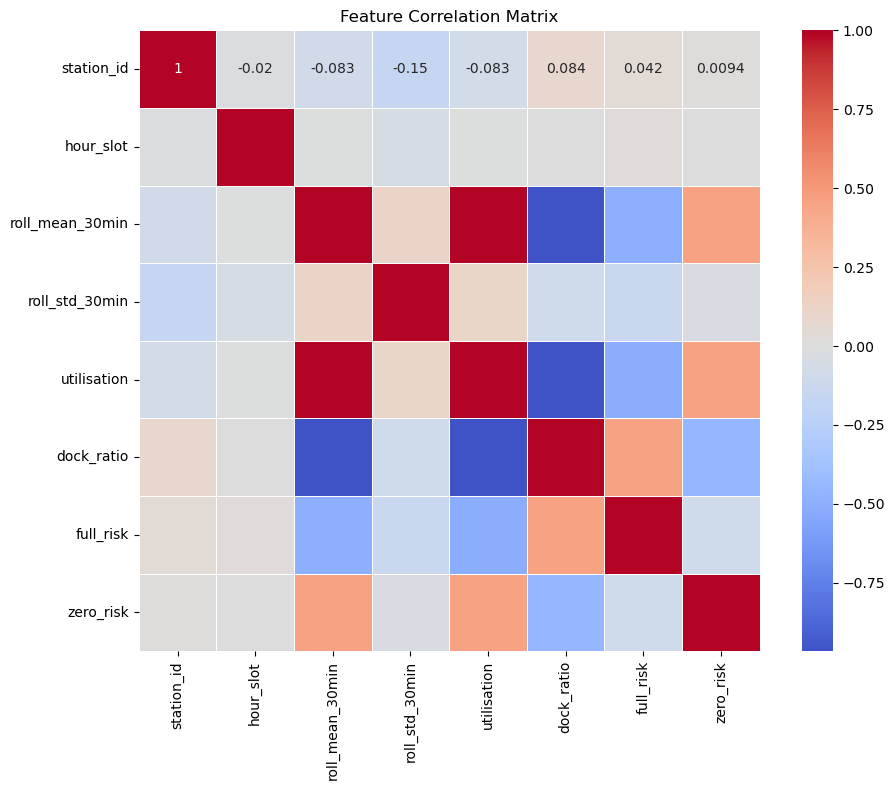

In [57]:
#Heatmap

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, 
            square=True, linewidths=0.5)
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

In [58]:
# High correlations (>0.7 or <-0.7)
high_corr = np.where(np.abs(corr_matrix) > 0.7)
print("\nHigh correlations (|r| > 0.7):")
for i, j in zip(*high_corr):
    if i != j:
        print(f"{corr_matrix.index[i]} ↔ {corr_matrix.columns[j]}: {corr_matrix.iloc[i,j]:.3f}")


High correlations (|r| > 0.7):
roll_mean_30min ↔ utilisation: 0.994
roll_mean_30min ↔ dock_ratio: -0.961
utilisation ↔ roll_mean_30min: 0.994
utilisation ↔ dock_ratio: -0.967
dock_ratio ↔ roll_mean_30min: -0.961
dock_ratio ↔ utilisation: -0.967


In [61]:
print("\n VIF SCORES ")

numeric_features = ['roll_mean_30min', 'roll_std_30min', 'utilisation', 
                   'dock_ratio', 'full_risk', 'zero_risk']
X = df_features[numeric_features].copy()

#X = add_constant(X)
#vif_data = pd.DataFrame()
#vif_data["feature"] = X.columns
#vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(len(X.columns))]

#print(vif_data.sort_values("VIF", ascending=False).round(2))


 VIF SCORES 


# Unable to calculate VIF as there are some NaN values